[Download this notebook](lasso_vs_ols_sparse_fa26.ipynb){download="lasso_vs_ols_sparse_fa26.ipynb"} to run the code or borrow from it.

**The question.** When does LASSO clearly beat ordinary least squares (OLS)? This dataset is built to show it: 60 inputs, only 5 of which matter, and only 70 training rows.

- **OLS** minimizes $\text{RSS}$.
- **LASSO** minimizes $\text{RSS} + \lambda \sum_j |\beta_j|$. Its penalty shrinks coefficients and sets some to exactly 0.

**The short answer.** LASSO won all 50 simulated datasets. Its median test $R^2$ was 0.826, compared with 0.159 for OLS, and its smallest lead on any dataset was 0.192.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Lasso, LassoCV, LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

BLUE, ORANGE, GREEN, GRAY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#c3c2b7", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.titlelocation": "left",
                     "axes.grid": True, "grid.color": "#e1e0d9", "axes.axisbelow": True, "legend.frameon": False})

TRUE_EFFECTS = [3, -3, 2, -2, 1.5]    # the coefficients of x1 to x5


def simulate(n=100, p=60, noise_sd=2, seed=1):
    """p independent inputs. Only x1 to x5 affect y. The rest are pure noise."""
    rng = np.random.default_rng(seed)
    names = [f"x{j}" for j in range(1, p + 1)]
    X = pd.DataFrame(rng.normal(size=(n, p)), columns=names)
    beta = pd.Series(0.0, index=names)
    beta.iloc[:5] = TRUE_EFFECTS
    y = pd.Series(5 + X.values @ beta.values + rng.normal(scale=noise_sd, size=n), name="y")
    return X, y, beta


def scores(model, X, y):
    """Return R-squared and RMSE of a fitted model on the data given."""
    pred = model.predict(X)
    return r2_score(y, pred), mean_squared_error(y, pred) ** 0.5


def fit_both(X, y):
    """Fit OLS and tuned LASSO on standardized inputs."""
    ols = make_pipeline(StandardScaler(), LinearRegression()).fit(X, y)
    lasso = make_pipeline(StandardScaler(), LassoCV(cv=5, random_state=1, max_iter=50000)).fit(X, y)
    return ols, lasso


X, y, beta = simulate()

# Part 1. Introduce the dataset

Each row is one simulated observation, and we predict `y`, so this is a regression problem.

| Variable | How it is made |
|:--|:--|
| `x1` to `x60` | Independent random draws from a standard normal distribution |
| `y` | $5 + 3x_1 - 3x_2 + 2x_3 - 2x_4 + 1.5x_5 + \varepsilon$, where $\varepsilon$ is normal with SD 2 |

So `x1` to `x5` are the **real inputs**, and `x6` to `x60` are 55 **noise inputs** with no connection to `y`. Unlike with real data, we know the true answer, so we can check each model's coefficients against it.

In [2]:
print("Rows:", X.shape[0], " Inputs:", X.shape[1], " Inputs that affect y:", (beta != 0).sum())
pd.concat([X[["x1", "x2", "x3", "x4", "x5", "x6", "x60"]], y], axis=1).head().round(3)

Rows: 100  Inputs: 60  Inputs that affect y: 5


,x1,x2,x3,x4,x5,x6,x60,y
0,0.346,0.822,0.330,-1.303,0.905,0.446,-0.314,6.458
1,0.054,0.273,-0.982,-1.107,0.200,-0.467,0.666,8.189
2,1.524,-1.525,-2.466,0.617,2.548,-1.001,1.317,11.339
3,0.493,0.161,-0.932,2.872,0.880,-1.139,-1.126,-1.889
4,0.096,-0.178,0.203,-1.606,1.812,-0.603,-0.310,13.059


In [3]:
# How strongly does each input track y? (top 8)
print(X.corrwith(y).sort_values(key=abs, ascending=False).head(8).round(3).to_string())

x1     0.508
x2    -0.463
x4    -0.372
x5     0.283
x3     0.220
x57   -0.201
x8     0.199
x46   -0.164


The five real inputs do have the strongest correlations with `y`. But noise inputs such as `x57` (−0.201) and `x8` (0.199) come close to `x3` (0.220) in this sample, purely by chance. With so few rows, an input that has nothing to do with `y` can look useful.

# Part 2. Explain the testing procedure

The same procedure is used for both models, so the contest is fair.

| Step | What happens | Why |
|:--|:--|:----|
| 1. Simulate | Draw 100 new rows | Each dataset is a fresh sample from the same process |
| 2. Split | Randomly assign 70% of rows to training and 30% to test | The test set shows performance on rows the model hasn't seen |
| 3. Standardize | Learn each input's mean and SD from the training rows only, then apply them to the test rows | The LASSO penalty treats inputs on the same scale, with no test information leaking in |
| 4. Fit OLS | Fit on the training rows | There is nothing to tune |
| 5. Tune and fit LASSO | Choose `alpha` by 5-fold cross-validation **within the training rows**, then refit | The test set plays no part in choosing `alpha` |
| 6. Score | Compute test $R^2$ and RMSE for both models | Same test rows for both, so any difference comes from the models |
| 7. Repeat | Run steps 1 to 6 on **50 simulated datasets** (seeds 1 to 50) | One dataset can be lucky |

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1)
print("Training rows:", len(X_train), "  Test rows:", len(X_test), "  Inputs:", X.shape[1])
print("Coefficients OLS must estimate (with intercept):", X.shape[1] + 1)
print("Training rows per coefficient: %.2f" % (len(X_train) / (X.shape[1] + 1)))

Training rows: 70   Test rows: 30   Inputs: 60
Coefficients OLS must estimate (with intercept): 61
Training rows per coefficient: 1.15


OLS has to estimate 61 coefficients from 70 rows, or about 1.15 rows per coefficient. That is the heart of its problem.

# Part 3. OLS results, tuning alpha, and LASSO coefficients

This part walks through a single dataset (`seed=1`). Part 4 repeats everything on all 50.

## 3a. OLS

In [5]:
ols, lasso = fit_both(X_train, y_train)
print("OLS train R2 = %.3f, RMSE = %.2f" % scores(ols, X_train, y_train))
print("OLS test  R2 = %.3f, RMSE = %.2f" % scores(ols, X_test, y_test))

# Divide by each input's SD to return to original units, so we can compare with the truth
sds = pd.Series(ols[0].scale_, index=X.columns)
ols_coef = pd.Series(ols[-1].coef_, index=X.columns) / sds
print("\n10 largest OLS coefficients:")
print(pd.DataFrame({"ols_coef": ols_coef, "true": beta}).sort_values("ols_coef", key=abs, ascending=False).head(10).round(3).to_string())

OLS train R2 = 0.983, RMSE = 0.70
OLS test  R2 = -1.243, RMSE = 7.05

10 largest OLS coefficients:
     ols_coef  true
x4     -3.882  -2.0
x1      3.267   3.0
x57    -2.066   0.0
x52     1.822   0.0
x7      1.683   0.0
x5      1.479   1.5
x15     1.438   0.0
x27    -1.413   0.0
x34    -1.367   0.0
x2     -1.266  -3.0


OLS fits the training rows almost perfectly ($R^2$ = 0.983), but its test $R^2$ is −1.243. A negative $R^2$ means its predictions are worse than simply guessing the average `y` for every row. This dataset is a bad one for OLS (the median over 50 datasets is 0.159, in Part 4), but it shows the pattern clearly.

The coefficients show why. Noise inputs such as `x57` (−2.066) and `x52` (1.822) get larger coefficients than some real inputs, and `x2`, whose true value is −3, comes out at only −1.266.

## 3b. Tuning alpha for LASSO

`LassoCV` tries 100 values of `alpha`. For each one, it fits on 4 of 5 folds of the training rows and measures the error on the fifth, rotating through all five. It then picks the `alpha` with the lowest average error.

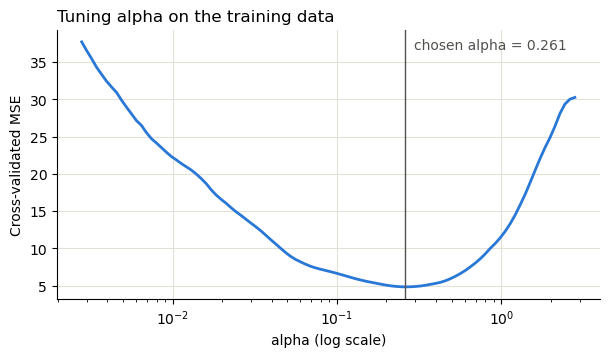

Chosen alpha: 0.261
LASSO train R2 = 0.895, RMSE = 1.71
LASSO test  R2 = 0.829, RMSE = 1.95


In [6]:
cv = lasso[-1]

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(cv.alphas_, cv.mse_path_.mean(axis=1), color=BLUE, lw=2)
ax.axvline(cv.alpha_, color=INK, lw=1)
ax.annotate(f"chosen alpha = {cv.alpha_:.3f}", (cv.alpha_, ax.get_ylim()[1]), xytext=(6, -14),
            textcoords="offset points", color=INK)
ax.set_xscale("log")
ax.set(xlabel="alpha (log scale)", ylabel="Cross-validated MSE", title="Tuning alpha on the training data")
plt.show()

print("Chosen alpha: %.3f" % cv.alpha_)
print("LASSO train R2 = %.3f, RMSE = %.2f" % scores(lasso, X_train, y_train))
print("LASSO test  R2 = %.3f, RMSE = %.2f" % scores(lasso, X_test, y_test))

Unlike in the `x3` notebook, this curve has a clear minimum, so tuning matters.

- **Too small:** the model is close to OLS and keeps noise inputs, and the error is several times higher than at the minimum.
- **Too large:** the real inputs are shrunk too far, so the model underfits.
- **The result on this dataset:** at `alpha` = 0.261, LASSO gives up training fit (0.895 vs 0.983) and gains far more on the test rows (0.829 vs −1.243).

## 3c. Plot the LASSO coefficients

The path plot uses standardized inputs, and the bar charts return to original units, so they can be compared with the true values.

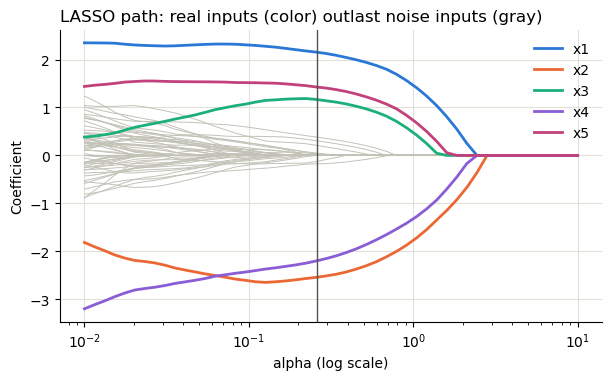

In [7]:
# Refit Lasso at many alphas on the standardized training data
Z_train = pd.DataFrame(StandardScaler().fit_transform(X_train), columns=X.columns)
alphas = np.logspace(-2, 1, 50)
path = pd.DataFrame([Lasso(alpha=a, max_iter=100000, tol=1e-6).fit(Z_train, y_train).coef_ for a in alphas],
                    index=alphas, columns=X.columns)

real = list(X.columns[:5])
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(path.index, path.drop(columns=real).values, color=GRAY, lw=0.7)
for term, color in zip(real, [BLUE, ORANGE, GREEN, "#8a5cd6", "#c2417c"]):
    ax.plot(path.index, path[term], color=color, lw=2, label=term)
ax.axvline(cv.alpha_, color=INK, lw=1)
ax.set_xscale("log"); ax.legend(loc="upper right")
ax.set(xlabel="alpha (log scale)", ylabel="Coefficient",
       title="LASSO path: real inputs (color) outlast noise inputs (gray)")
plt.show()

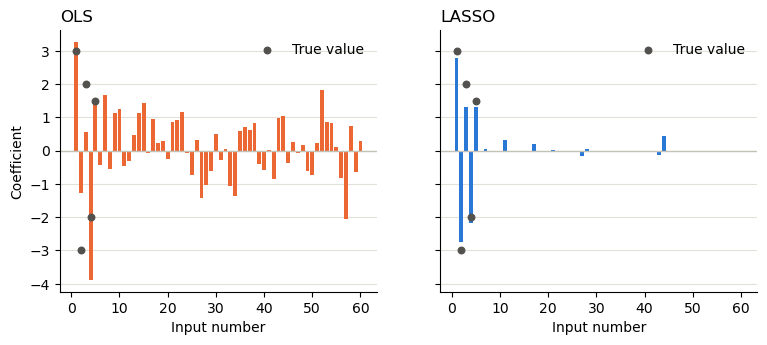

LASSO kept 13 of 60 inputs
    true    ols  lasso
x1   3.0  3.267  2.768
x2  -3.0 -1.266 -2.734
x3   2.0  0.557  1.309
x4  -2.0 -3.882 -2.168
x5   1.5  1.479  1.313


In [8]:
lasso_coef = pd.Series(lasso[-1].coef_, index=X.columns) / sds
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
xs = np.arange(1, X.shape[1] + 1)
for ax, coef, color, name in zip(axes, [ols_coef, lasso_coef], [ORANGE, BLUE], ["OLS", "LASSO"]):
    ax.bar(xs, coef, color=color, width=0.8)
    ax.scatter(xs[:5], beta.iloc[:5], color=INK, s=22, zorder=3, label="True value")
    ax.axhline(0, color=GRAY, lw=1); ax.grid(axis="x", visible=False); ax.legend(loc="upper right")
    ax.set(xlabel="Input number", title=name)
axes[0].set_ylabel("Coefficient")
plt.show()

print(f"LASSO kept {(lasso_coef != 0).sum()} of {len(lasso_coef)} inputs")
print(pd.DataFrame({"true": beta, "ols": ols_coef, "lasso": lasso_coef}).head(5).round(3).to_string())

- **The path:** the noise inputs shrink to 0 first, by the time `alpha` reaches about 1. The real inputs last much longer.
- **The bars:** OLS scatters sizable coefficients across all 60 inputs, so the real ones are hard to pick out. LASSO's five real inputs stand out, and only a few small bars remain elsewhere.
- **Not perfect:** LASSO kept 13 inputs here, the 5 real ones plus 8 noise inputs. Its real coefficients are also pulled toward 0: `x3` is 1.309, where the truth is 2.

# Part 4. Compare OLS and tuned LASSO

This repeats the procedure from Part 2 on 50 simulated datasets, with `alpha` retuned on each one.

In [9]:
rows, ols_coefs, lasso_coefs = [], {}, {}
for seed in range(1, 51):
    X_s, y_s, _ = simulate(seed=seed)
    Xa, Xb, ya, yb = train_test_split(X_s, y_s, test_size=0.3, random_state=seed)
    m_ols, m_lasso = fit_both(Xa, ya)
    ols_coefs[seed] = pd.Series(m_ols[-1].coef_ / m_ols[0].scale_, index=X.columns)
    lasso_coefs[seed] = pd.Series(m_lasso[-1].coef_ / m_lasso[0].scale_, index=X.columns)
    rows.append({"seed": seed,
                 "ols_train": scores(m_ols, Xa, ya)[0], "lasso_train": scores(m_lasso, Xa, ya)[0],
                 "ols_r2": scores(m_ols, Xb, yb)[0], "lasso_r2": scores(m_lasso, Xb, yb)[0],
                 "ols_rmse": scores(m_ols, Xb, yb)[1], "lasso_rmse": scores(m_lasso, Xb, yb)[1],
                 "alpha": m_lasso[-1].alpha_, "kept": (m_lasso[-1].coef_ != 0).sum()})
res = pd.DataFrame(rows).set_index("seed")
ols_coefs, lasso_coefs = pd.DataFrame(ols_coefs), pd.DataFrame(lasso_coefs)

table = pd.DataFrame({
    "median test R2": [res.ols_r2.median(), res.lasso_r2.median()],
    "worst test R2": [res.ols_r2.min(), res.lasso_r2.min()],
    "median test RMSE": [res.ols_rmse.median(), res.lasso_rmse.median()],
    "avg train-test gap": [(res.ols_train - res.ols_r2).mean(), (res.lasso_train - res.lasso_r2).mean()],
}, index=["OLS", "LASSO"]).round(3)
print(table.to_string())
print("\nLASSO higher test R2 on", (res.lasso_r2 > res.ols_r2).sum(), "of 50 datasets")
print("Smallest LASSO lead in test R2: %.3f" % (res.lasso_r2 - res.ols_r2).min())
print("Median alpha: %.3f   Average inputs kept: %.1f of %d" % (res.alpha.median(), res.kept.mean(), X.shape[1]))

       median test R2  worst test R2  median test RMSE  avg train-test gap
OLS             0.159         -2.029             5.134               1.142
LASSO           0.826          0.544             2.248               0.083

LASSO higher test R2 on 50 of 50 datasets
Smallest LASSO lead in test R2: 0.192
Median alpha: 0.277   Average inputs kept: 16.7 of 60


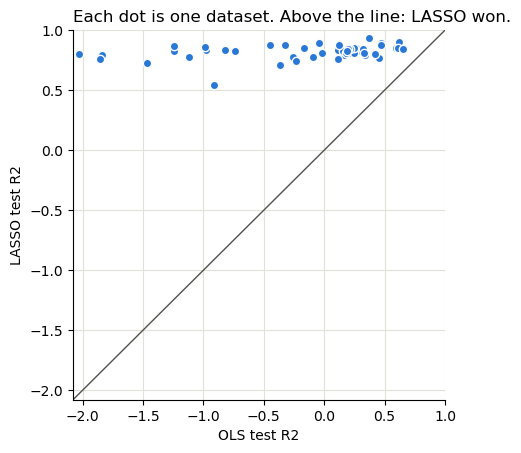

Datasets where OLS test R2 is below 0: 21 of 50


In [10]:
# Each dot is one simulated dataset.
lim = [min(res.ols_r2.min(), res.lasso_r2.min()) - 0.05, 1]
fig, ax = plt.subplots(figsize=(4.8, 4.8))
ax.scatter(res.ols_r2, res.lasso_r2, color=BLUE, s=36, edgecolor="#fcfcfb", lw=1)
ax.plot(lim, lim, color=INK, lw=1); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set(xlabel="OLS test R2", ylabel="LASSO test R2", title="Each dot is one dataset. Above the line: LASSO won.")
plt.show()
print("Datasets where OLS test R2 is below 0:", (res.ols_r2 < 0).sum(), "of 50")

LASSO won every time, and by a wide margin. Even LASSO's worst dataset ($R^2$ = 0.544) was better than OLS's median (0.159), and OLS's test $R^2$ fell below 0 on 21 of 50 datasets.

For reference, the best $R^2$ any model could expect here is about 0.876, the share of the variance in `y` that isn't noise. LASSO's 0.826 is close to that.

# Part 5. Summarize the variables in the two models

We know the true coefficients, so we can check how each model did. These are in original units, over the 50 datasets.

In [11]:
real = beta[beta != 0].index
noise = beta[beta == 0].index
summary = pd.DataFrame({"true": beta[real], "ols_mean": ols_coefs.loc[real].mean(axis=1), "ols_sd": ols_coefs.loc[real].std(axis=1),
                        "lasso_mean": lasso_coefs.loc[real].mean(axis=1), "lasso_sd": lasso_coefs.loc[real].std(axis=1),
                        "pct_kept": (lasso_coefs.loc[real] != 0).mean(axis=1) * 100})
print(summary.round(3).to_string())

pct_kept_noise = (lasso_coefs.loc[noise] != 0).mean(axis=1) * 100
print("\nNoise inputs (55 of them):")
print("Average kept per dataset:  OLS 55.0   LASSO %.1f" % (lasso_coefs.loc[noise] != 0).sum().mean())
print("Average |coefficient|:     OLS %.3f  LASSO %.3f" % (ols_coefs.loc[noise].abs().mean().mean(), lasso_coefs.loc[noise].abs().mean().mean()))
print("Kept most often: %.0f%% of datasets   Kept least often: %.0f%%" % (pct_kept_noise.max(), pct_kept_noise.min()))
print("\nDatasets where LASSO kept all 5 real inputs:", (lasso_coefs.loc[real] != 0).all().sum(), "of 50")

err = lambda c: np.sqrt(((c.sub(beta, axis=0)) ** 2).sum())
print("Median distance from the true coefficients:  OLS %.2f   LASSO %.2f" % (err(ols_coefs).median(), err(lasso_coefs).median()))

    true  ols_mean  ols_sd  lasso_mean  lasso_sd  pct_kept
x1   3.0     3.008   0.854       2.651     0.289     100.0
x2  -3.0    -3.015   0.644      -2.633     0.287     100.0
x3   2.0     1.975   0.808       1.721     0.258     100.0
x4  -2.0    -1.993   0.658      -1.598     0.387     100.0
x5   1.5     1.409   0.673       1.126     0.280     100.0

Noise inputs (55 of them):
Average kept per dataset:  OLS 55.0   LASSO 11.7
Average |coefficient|:     OLS 0.545  LASSO 0.031
Kept most often: 36% of datasets   Kept least often: 8%

Datasets where LASSO kept all 5 real inputs: 50 of 50
Median distance from the true coefficients:  OLS 4.97   LASSO 1.18


- **Finding the real inputs:** LASSO kept all 5 real inputs on all 50 datasets.
- **Removing noise:** LASSO kept 11.7 of the 55 noise inputs on average, while OLS keeps all 55. Their coefficients are tiny, averaging 0.031 in absolute value, compared with 0.545 under OLS.
- **Closer to the truth overall:** the median distance from the true coefficients is 1.18 for LASSO and 4.97 for OLS.

**LASSO doesn't find the exact answer.** No noise input was kept on every dataset, but each was kept on 8% to 36% of them, so about 12 slip in each time. Cross-validation chooses `alpha` for prediction, not for picking out exactly the real inputs. Don't treat every kept input as a real one.

# Part 6. Explain why LASSO works better

**OLS fits noise.** Its median gap between train and test $R^2$ is 0.828, compared with 0.073 for LASSO.

In [12]:
print(pd.DataFrame({"median train R2": [res.ols_train.median(), res.lasso_train.median()],
                    "median test R2": [res.ols_r2.median(), res.lasso_r2.median()],
                    "median gap": [(res.ols_train - res.ols_r2).median(), (res.lasso_train - res.lasso_r2).median()]},
                   index=["OLS", "LASSO"]).round(3).to_string())

sd = pd.DataFrame({"OLS": ols_coefs.std(axis=1), "LASSO": lasso_coefs.std(axis=1)})
print("\nMedian coefficient SD over the 50 datasets:")
print(sd.median().round(3).to_string())

       median train R2  median test R2  median gap
OLS              0.983           0.159       0.828
LASSO            0.907           0.826       0.073

Median coefficient SD over the 50 datasets:
OLS      0.699
LASSO    0.088


**It's a trade of bias for variance.** The table in Part 5 shows both sides.

| | OLS | LASSO |
|:--|:--|:--|
| **Bias:** average `x1` estimate (truth 3) | 3.008, about right | 2.651, too small |
| **Variance:** SD of the `x1` estimate | 0.854 | 0.289 |
| Typical coefficient SD, all inputs | 0.699 | 0.088 |

OLS is right *on average*, but any one dataset gives only one estimate, and that estimate can be far off. LASSO accepts a small, consistent error toward 0 and in return has much lower variance. Here the trade is very favorable: a typical coefficient varies about 8 times less.

**Why the design favors LASSO.**

- **Few rows per coefficient:** with 70 rows and 61 coefficients, OLS has almost no data to spare, so its coefficients and predictions are very sensitive to the training rows.
- **Mostly noise inputs:** the true model is sparse, so setting most coefficients to 0 costs nothing. OLS, by contrast, pays for 55 coefficients that should be 0.

**More data closes the gap.** The next chart keeps the same 60 inputs and adds rows, using 20 datasets at each size.

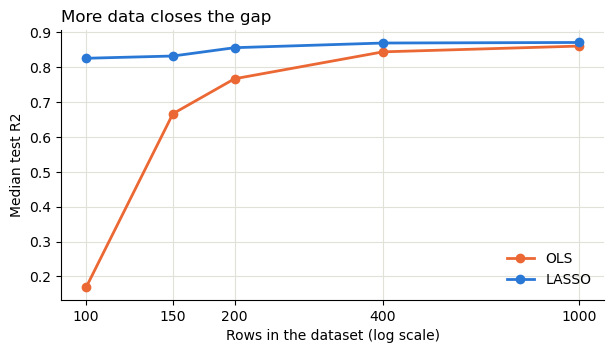

        OLS  LASSO  LASSO wins (of 20)
rows                                  
100   0.168  0.826                  20
150   0.667  0.832                  20
200   0.767  0.856                  20
400   0.844  0.870                  20
1000  0.861  0.871                  20


In [13]:
# Same process, with more and more rows. The 70/30 split and the 60 inputs stay the same.
sizes = [100, 150, 200, 400, 1000]
curve = []
for n in sizes:
    r_ols, r_lasso = [], []
    for seed in range(1, 21):
        X_s, y_s, _ = simulate(n=n, seed=seed)
        Xa, Xb, ya, yb = train_test_split(X_s, y_s, test_size=0.3, random_state=seed)
        m_ols, m_lasso = fit_both(Xa, ya)
        r_ols.append(scores(m_ols, Xb, yb)[0]); r_lasso.append(scores(m_lasso, Xb, yb)[0])
    curve.append({"rows": n, "OLS": np.median(r_ols), "LASSO": np.median(r_lasso),
                  "LASSO wins (of 20)": int((np.array(r_lasso) > np.array(r_ols)).sum())})
curve = pd.DataFrame(curve).set_index("rows")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(curve.index, curve.OLS, color=ORANGE, lw=2, marker="o", label="OLS")
ax.plot(curve.index, curve.LASSO, color=BLUE, lw=2, marker="o", label="LASSO")
ax.set_xscale("log"); ax.set_xticks(sizes, sizes); ax.minorticks_off(); ax.legend()
ax.set(xlabel="Rows in the dataset (log scale)", ylabel="Median test R2", title="More data closes the gap")
plt.show()
print(curve.round(3).to_string())

At 100 rows, the gap is 0.826 vs 0.168. At 1,000 rows, it's only 0.871 vs 0.861, close to the best possible 0.876. LASSO still wins all 20 datasets at that size, since the noise inputs still cost OLS a little, but the practical difference is small. **The value of LASSO depends on how many rows you have per coefficient.**

# Takeaways

- **LASSO is the clear winner when rows are scarce and most inputs are noise.** It won 50 of 50 datasets, with a median test $R^2$ of 0.826 vs 0.159.
- **A high training $R^2$ means little here.** OLS reached 0.983 on training rows and only 0.159 on test rows.
- **LASSO trades bias for variance.** Its estimates are a bit too small, but far more stable.
- **It finds the real inputs, plus some extras.** It kept all 5 real inputs every time, along with about 12 noise inputs.
- **The advantage has limits.** It shrinks as rows are added, and it vanished in the `x3` notebook, where OLS had little variance to cut.